# 5. Bring your own problem: a new task with no exact benchmark

On a new problem there is no exact frontier to measure the optimization error against. This notebook walks through
what a practitioner can still do, and what can be claimed, on a task written from scratch:

1. write the simulator as an ordinary Gymnasium environment,
2. state the budget, the horizon and the requirement, and check the conditions under which another method is better,
3. evaluate simple structured policies first, because they are candidates too,
4. run short pilot runs at a few prices with PPO through the wrapper,
5. read the pilot runs: frontier, price–risk law, and whether raising the price can reach the tolerance,
6. validate every inspected candidate with a shared error and write the report, without claiming optimality.

**The task.** A fishery operates for a season of $H=52$ weeks under a seasonal **bycatch cap**. Each week the
operator chooses a fishing effort $a\in[0,1]$. Revenue has diminishing returns in effort and follows a fluctuating
market price. Bycatch is random and proportional to effort. If cumulative bycatch exceeds the cap, the fishery is
**closed** for the rest of the season, and the regulator charges a penalty $m$ for every remaining week. That
penalty is the price of failure risk, a quantity of the application. The requirement: the probability of a closure
within the season must stay below 5%.

Requires the RL extras. The notebook takes about thirteen minutes on one CPU core.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import gymnasium as gym
import torch
from stable_baselines3 import PPO
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize

import bpg
from bpg import BudgetSpec, Requirement, Stage, BudgetWrapper, plan, evaluate, interpret, sb3_policy
from bpg.callbacks import BudgetMonitor
from bpg.convergence import seed_dispersion
from bpg.frontier import Run, check_runs, price_sequence_check

torch.set_num_threads(1)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

## 1. The simulator

An ordinary `gymnasium.Env`. It knows nothing about budgets: it returns the revenue as its reward and reports the
week's bycatch in `info`. The wrapper adds the budget.

In [2]:
class Fishery(gym.Env):
    """Observation (price index s, week fraction); action effort a in [0, 1]; reward = revenue in [0, 1];
    info['bycatch'] = 0.05 a xi with xi exponential with mean one."""
    H = 52

    def __init__(self):
        self.observation_space = gym.spaces.Box(np.array([-1.0, 0.0], np.float32), np.array([1.0, 1.0], np.float32))
        self.action_space = gym.spaces.Box(0.0, 1.0, (1,), np.float32)

    def reset(self, *, seed=None, options=None):
        super().reset(seed=seed)
        self.s, self.t = 0.0, 0
        return np.array([self.s, 0.0], np.float32), {}

    def step(self, action):
        a = float(np.clip(np.asarray(action).reshape(-1)[0], 0.0, 1.0))
        revenue = (1.0 + 0.4 * self.s) * math.sqrt(a) / 1.4
        bycatch = 0.05 * a * self.np_random.exponential(1.0)
        self.s = 0.8 * self.s + 0.2 * self.np_random.uniform(-1.0, 1.0)
        self.t += 1
        return np.array([self.s, self.t / self.H], np.float32), revenue, False, False, dict(bycatch=bycatch)


bycatch = lambda obs, action, next_obs, reward, info: [info["bycatch"]]

## 2. The budget, the horizon and the requirement

The cap is $b=1.2$, the weekly discount $\beta=0.995$, and revenue lies in $[0,1]$, so $\bar u=1$. The task ends
after $H=52$ actions: `BudgetSpec(horizon=52)` makes the wrapper end episodes there and charge a closure at week $t$
the remaining discounted penalty $m(1-\beta^{H-t})/(1-\beta)$. The requirement is $p_{51}\le0.05$: no closure within
the 52 weeks, with probability at least 95%.

In [3]:
spec = BudgetSpec(budgets=[1.2], beta=0.995, ubar=1.0, horizon=Fishery.H)
S_H = (1 - spec.beta ** spec.horizon) / (1 - spec.beta)
req = Requirement(T=51, alpha=0.05, zeta=0.05, family=12)       # twelve candidates will be inspected
p = plan(spec, req, sup_U=spec.ubar * S_H, stage=Stage(m=2.0), failure_permissible_at_deployment=True,
         violations_during_training_matter=False, loss_grows_with_excess_consumption=False,
         model_known_and_small=False,          # the simulator is treated as a black box
         episode_earnings=S_H / 2)             # about half the largest possible revenue of a season
print(p.explain())

Requirement: p_T <= 0.05 at T = 51 (52 actions), validation error 0.05 shared by 12 statements; kind = finite.
When another method is the better choice [paper, 'Which formulation to prefer']:
  [does not apply] no failure is permissible and a controlled-invariant set is known: an almost-sure method (an infinite failure penalty, a control-barrier safety layer, or a method that learns which actions keep probability-one budget constraints). Reason: a finite price prices failure risk and does not prohibit failure; a class of full-support policies can have a positive risk floor.
  [not stated] a prescribed level is attainable with slack and the multiplier's step can be tuned: an adaptive multiplier (a Lagrangian chance-constrained policy gradient). Reason: a fixed price leaves the attained risk to the optimizer, and unused risk costs utility; with too large a step the multiplier increases without bound when the initial policy fails often, as in the fuel-tank study.
  [does not apply] violat

None of the cases of the paper's *Which formulation to prefer* applies as stated. We treat the simulator as a black
box, as one would a simulator one did not write; with a known model and a small state an exact dynamic program would
be the better choice. A simple structured policy may still do as well as the learner; we check that next. The
conservative starting price from the price–risk law is very large here, because the only bound on the utility at
stake is the trivial one, $\bar u S_H$. We use short pilot runs at a few prices instead.

## 3. Structured policies first

A constant effort, and a **pacing rule** that spends the remaining cap evenly over the remaining weeks with a
safety factor $k$: $a=\min\{1, z/(k\cdot0.05\cdot\text{weeks left})\}$. They are candidates like any other, and they
give a lower bound on what the optimum achieves.

In [4]:
def make_env(stage):
    return BudgetWrapper(Fishery(), bycatch, spec, stage, observe="fraction")


def constant(effort):
    return lambda obs: np.array([effort], np.float32)


def pacing(k):
    def f(obs):
        weeks_left = max(1.0, Fishery.H * (1.0 - float(obs[1])))
        z = float(obs[2]) * spec.budgets[0]
        return np.array([min(1.0, z / (k * 0.05 * weeks_left))], np.float32)
    return f


rules = {"constant 0.3": constant(0.3), "constant 0.5": constant(0.5), "pacing k = 1.5": pacing(1.5), "pacing k = 2.5": pacing(2.5)}
pilot_stage = Stage(m=2.0)
rule_evals = {name: evaluate(lambda: make_env(pilot_stage), pol, 4000, spec=spec, stage=pilot_stage, seed=1, T=51)
              for name, pol in rules.items()}
for name, e in rule_evals.items():
    print(f"{name:15s} closure p_51 = {e.p_T:.4f}   revenue U = {e.U:.2f}   V_m (m = 2) = {e.V_m:.2f}")

constant 0.3    closure p_51 = 0.0003   revenue U = 17.95   V_m (m = 2) = 17.95
constant 0.5    closure p_51 = 0.7030   revenue U = 21.10   V_m (m = 2) = 10.92
pacing k = 1.5  closure p_51 = 0.1595   revenue U = 21.05   V_m (m = 2) = 20.62
pacing k = 2.5  closure p_51 = 0.0138   revenue U = 18.74   V_m (m = 2) = 18.71


## 4. Pilot runs at a few prices

Three prices, two seeds each, PPO with the settings of notebook 2 and discount $\beta$ (the episodes end at the
physical horizon, not by a geometric clock). The fishery's state includes the week: the wrapper appends the
remaining cap, so the policy sees price, week and reserve.

In [5]:
def train(stage, seed, steps=1_000_000, n_envs=32):
    venv = DummyVecEnv([lambda: make_env(stage) for _ in range(n_envs)])
    venv.seed(seed)
    venv = VecNormalize(venv, norm_obs=False, norm_reward=True, clip_reward=1e9, gamma=spec.beta)
    mon = BudgetMonitor(spec.beta, stage.m, horizon=spec.horizon)
    ppo = PPO("MlpPolicy", venv, seed=seed, n_steps=256, batch_size=1024, n_epochs=10, learning_rate=lambda p: 3e-4 * p,
              gamma=spec.beta, gae_lambda=0.95, clip_range=0.2, ent_coef=0.0,
              policy_kwargs=dict(net_arch=[64, 64], log_std_init=-1.0), device="cpu", verbose=0)
    ppo.learn(total_timesteps=steps, callback=[mon])
    return ppo, mon


prices, seeds = (0.5, 2.0, 8.0), (0, 1)
learned = {}
for m_ in prices:
    st = Stage(m=m_)
    for sd in seeds:
        ppo, mon = train(st, sd)
        e = evaluate(lambda: make_env(st), sb3_policy(ppo), 4000, spec=spec, stage=st, seed=100 + sd, T=51)
        learned[(m_, sd)] = (ppo, mon, e)
        print(f"m = {m_:<4g} seed {sd}: closure p_51 = {e.p_T:.4f}, revenue U = {e.U:.2f}, V_m = {e.V_m:.2f}")

m = 0.5  seed 0: closure p_51 = 0.2610, revenue U = 21.33, V_m = 20.98


m = 0.5  seed 1: closure p_51 = 0.2248, revenue U = 21.31, V_m = 21.03


m = 2    seed 0: closure p_51 = 0.0705, revenue U = 21.00, V_m = 20.70


m = 2    seed 1: closure p_51 = 0.0413, revenue U = 20.90, V_m = 20.72


m = 8    seed 0: closure p_51 = 0.0302, revenue U = 20.59, V_m = 20.11


m = 8    seed 1: closure p_51 = 0.0132, revenue U = 20.54, V_m = 20.30


## 5. Reading the pilot runs

**The frontier.** Every fixed-price optimum lies on the frontier of utility against risk (*Fixed price of failure risk*).
With no exact frontier, the structured policies and the learned ones together trace what is attainable.

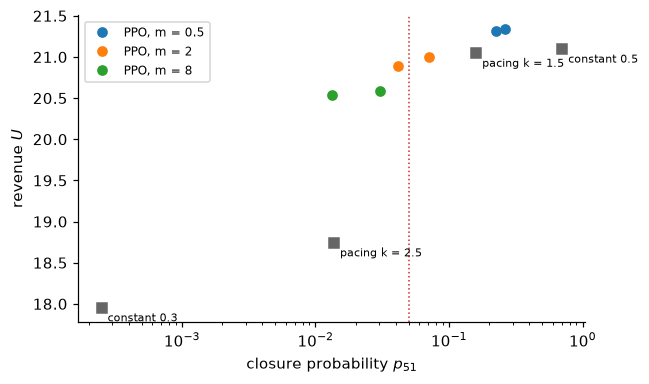

In [6]:
fig, ax = plt.subplots(figsize=(6, 3.6))
for name, e in rule_evals.items():
    ax.plot(max(e.p_T, 1e-4), e.U, "s", color="0.4"); ax.annotate(name, (max(e.p_T, 1e-4), e.U), textcoords="offset points", xytext=(4, -9), fontsize=7)
for i, m_ in enumerate(prices):
    pts = [learned[(m_, sd)][2] for sd in seeds]
    ax.plot([max(e.p_T, 1e-4) for e in pts], [e.U for e in pts], "o", color=f"C{i}", label=f"PPO, m = {m_:g}")
ax.axvline(0.05, color="C3", ls=":", lw=1)
ax.set_xscale("log"); ax.set_xlabel("closure probability $p_{51}$"); ax.set_ylabel("revenue $U$"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**The price–risk law and monotonicity.** `check_runs` compares the learned runs with the law, using the safest
structured policy as the comparison policy, and flags dominated runs. Each run carries the standard error of its
estimated risk, and the comparison allows two of them. The optimization error is unknown, so the law is checked at
$\delta=0$: a run above the law at $\delta=0$ is not an exact optimizer at its price, and the excess says its $\delta$
is positive. A dominated run says the same.

In [7]:
runs = [Run(m=m_, q_beta=e.q_beta, U=e.U, I_m=e.I_m, label=f"seed {sd}", extra=dict(q_se=e.q_se)) for (m_, sd), (_, _, e) in learned.items()]
best_rule = min(rule_evals.values(), key=lambda e: e.q_beta)
chk = check_runs(runs, beta=spec.beta, sup_U=spec.ubar * S_H, U0=best_rule.U, q0=best_rule.q_beta, delta=0.0, ubar=spec.ubar)
print(chk.explain())

m=0.5      q=0.2039  U-I=21.33  law bound=0.2796
m=0.5      q=0.1754  U-I=21.31  law bound=0.2796
m=2        q=0.05491  U-I=21  law bound=0.07004
m=2        q=0.03213  U-I=20.9  law bound=0.07004
m=8        q=0.02354  U-I=20.59  law bound=0.01766  (violates the price-risk law)
m=8        q=0.01033  U-I=20.54  law bound=0.01766
monotonicity in the price: consistent within the stated optimization errors [paper, 'Fixed price of failure risk' (monotonicity in the price)]
a fixed-price optimum lies on the frontier of U - I_m against q_beta; a point strictly below another with no greater risk indicates optimization error (or a non-optimal policy), not a property of the formulation


**Can raising the price reach the tolerance?** The condition of the paper's *Price sequences reaching a tolerance* is that the charged errors
grow slower than the price. Without an exact optimum, a **lower bound** on each run's optimization error is its
shortfall from the best structured policy at the same price (the optimum is at least as good). If even that lower
bound grows in proportion to the price, raising the price is not the remedy.

In [8]:
def value_at(policy, m_):
    st = Stage(m=m_)
    return evaluate(lambda: make_env(st), policy, 4000, spec=spec, stage=st, seed=7, T=51).V_m


best_rule_value = {m_: max(value_at(pol, m_) for pol in rules.values()) for m_ in prices}
shortfall_lb = {m_: max(0.0, best_rule_value[m_] - max(learned[(m_, sd)][2].V_m for sd in seeds)) for m_ in prices}
for m_ in prices:
    print(f"m = {m_:<4g}: best structured V_m = {best_rule_value[m_]:.2f}, best learned V_m = {max(learned[(m_, sd)][2].V_m for sd in seeds):.2f}, "
          f"shortfall lower bound = {shortfall_lb[m_]:.2f}")
print(price_sequence_check(list(shortfall_lb), list(shortfall_lb.values())).explain())

m = 0.5 : best structured V_m = 20.94, best learned V_m = 21.03, shortfall lower bound = 0.00
m = 2   : best structured V_m = 20.62, best learned V_m = 20.72, shortfall lower bound = 0.00
m = 8   : best structured V_m = 19.33, best learned V_m = 20.30, shortfall lower bound = 0.00
m=0.5      charged=0  charged/m=0
m=2        charged=0  charged/m=0
m=8        charged=0  charged/m=0
no charged error was measured at any price (zero shortfalls, or zero lower bounds on them): the check says nothing about whether raising the price can reach a tolerance [paper, 'Price sequences reaching a tolerance']


Read this result as it comes out. If a structured rule beats the learner at every price, use the structure, as
the paper advises for a known model, and keep the toolbox for its certificates and validation, which apply to any
policy. If the learner beats the rules, the shortfall lower bound is zero and the check reports that it says nothing
about $\delta$; the dominance flags above remain the evidence of optimization error.

## 6. Validate every inspected candidate, then report

Twelve candidates were inspected: four rules, six learned policies, and the mean-action versions of the two we
might deploy. They share the validation error (`family=12`). Validation is over the full 52 weeks with fresh
episodes; there is no geometric clock, so $p_{51}$ is tested directly.

In [9]:
pool = {name: (pol, pilot_stage) for name, pol in rules.items()}
for (m_, sd), (ppo, _, _) in learned.items():
    pool[f"PPO m = {m_:g}, seed {sd}"] = (sb3_policy(ppo), Stage(m=m_))
ppo_pick, mon_pick, _ = learned[(2.0, 0)]
pool["PPO m = 2, seed 0, mean action"] = (sb3_policy(ppo_pick, deterministic=True), Stage(m=2.0))
ppo_alt = learned[(8.0, 0)][0]
pool["PPO m = 8, seed 0, mean action"] = (sb3_policy(ppo_alt, deterministic=True), Stage(m=8.0))
assert len(pool) == req.family
validated = {}
for name, (pol, st) in pool.items():
    e = evaluate(lambda: make_env(st), pol, 10_000, spec=spec, stage=st, seed=1000, T=51)
    v = e.validate(req.alpha, req.zeta, req.family)
    validated[name] = (e, v)
    print(f"{name:32s} p_51 = {e.p_T:.4f}  upper bound {v.upper:.4f}  {'CERTIFIED' if v.passed else 'not certified'}   revenue U = {e.U:.2f}")

constant 0.3                     p_51 = 0.0002  upper bound 0.0009  CERTIFIED   revenue U = 17.95


constant 0.5                     p_51 = 0.6983  upper bound 0.7104  not certified   revenue U = 21.08


pacing k = 1.5                   p_51 = 0.1651  upper bound 0.1751  not certified   revenue U = 21.04


pacing k = 2.5                   p_51 = 0.0127  upper bound 0.0160  CERTIFIED   revenue U = 18.74


PPO m = 0.5, seed 0              p_51 = 0.2644  upper bound 0.2762  not certified   revenue U = 21.33


...

PPO m = 2, seed 1                p_51 = 0.0460  upper bound 0.0518  not certified   revenue U = 20.91


PPO m = 8, seed 0                p_51 = 0.0282  upper bound 0.0329  CERTIFIED   revenue U = 20.56


PPO m = 8, seed 1                p_51 = 0.0155  upper bound 0.0191  CERTIFIED   revenue U = 20.56


PPO m = 2, seed 0, mean action   p_51 = 0.0407  upper bound 0.0462  CERTIFIED   revenue U = 21.48


PPO m = 8, seed 0, mean action   p_51 = 0.0074  upper bound 0.0100  CERTIFIED   revenue U = 21.11


The deployable choice is the certified candidate with the highest revenue, chosen **after** the error was allocated
over all twelve. The report states what this evidence establishes. The optimization error is unknown, so the report
makes no optimality claim; the seeds' dispersion and the training trace are evidence about these runs.

In [10]:
certified = {k: ev for k, ev in validated.items() if ev[1].passed}
choice = max(certified, key=lambda k: certified[k][0].U) if certified else max(validated, key=lambda k: -validated[k][1].upper)
e_choice = validated[choice][0]
st_choice = pool[choice][1]
print("choice:", choice, "\n")
trends = None
if choice.startswith("PPO"):
    m_c, sd_c = st_choice.m, int(choice.split("seed ")[1].split(",")[0])
    trends = learned[(m_c, sd_c)][1].diagnostics(window=40)
rep = interpret(spec, req, st_choice, e_choice, delta=None, trends=trends, candidate_name=choice,
                seeds={f"closure probability at m = {m_:g}": seed_dispersion([learned[(m_, sd)][2].p_T for sd in seeds]) for m_ in prices})
print(rep.text())

choice: PPO m = 2, seed 0, mean action 

Candidate under price m = 2; requirement p_51 <= 0.05 at error 0.05/12.

Measured on fresh episodes:
  n=10000: p_T(T=51)=0.0407 (407 failures counted for p_T), q_beta=0.03161, U=21.48±0.015, I_m=0, V_m=21.36±0.018, mean length 52.0
  near-exhaustion (min reserve <=): 0.02b: 0.116, 0.05b: 0.335, 0.1b: 0.787, 0.2b: 0.998

Verdict: CERTIFIED by direct validation at the specified horizon.

In what sense the candidate is a solution:
  - Optimization error is unknown: no optimality or convergence claim is made for this candidate. The finite-price objective trades stopped utility and interior loss against failure risk; direct validation assesses the executed candidate independently of optimization.

Evidence and bounds:
  - direct validation: 407 failures in 10000 episodes through action 51; exact binomial upper endpoint 0.0462 at error 0.00417 (resolution floor 0.000548); passes the tolerance 0.05
  - training trace, V_m: no trend detectable at two s

## What can be claimed on a new problem

* **Established:** the deployed candidate's closure probability within the season is at most the validated upper
  bound, at the stated confidence, jointly with the other inspected candidates; the value certificate under the
  physical horizon, when informative, says the same from the value.
* **Conditional:** the fixed-price reading (optimal at the risk it attains) holds up to an optimization error that is
  not measured here. A structured policy gives a lower bound on it, never an upper bound.
* **Not established:** behavior under a different simulator (model error), other horizons or seasons, other
  candidates (including the same network with its dispersion removed), and convergence of the training run.

If no candidate is certified: validate on more episodes (the resolution floor may be the limit), raise the price if
the pilot runs show that the learner's error does not grow with it, or deploy the structured policy if it is
certified and the learner does not beat it.